# Reconstrução de imagens de tomografia

O objetivo é aplicar métodos de reconstrução de imagens de tomografia. Para aplicar esses métodos, primeiro é preciso ter um alvo definido e obter dados desse alvo. Em um contexto médico, essa parte é feita pela máquina de tomografia, que utiliza feixes de partículas que atravessam o alvo e exibem diferentes intensidades consoante a atenuação do meio e também o angulo de incidência. No ambito deste notebook, essa parte simulada fazendo a rotação do fantoma e, para cada angulo, faz-se a acumulação das intensidades dos píxeis da figura. Essas intensidades são dispostas em um sinograma.

A primeira abordagem consiste na utilização de uma retroprojeção simples. No entanto, esse método demonstra baixa resolução, mesmo para um número grande de ângulos de incidência. 

O segundo método consiste em uma retroprojeção filtrada, que utiliza da transformada de Radon. Esse método já demonstra uma resolução maior, mesmo para um baixo número de ângulos de incidência.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import scipy

### Primeiro cria-se uma imagem para usar como fantoma. Também é feita a importação de uma imagem. 

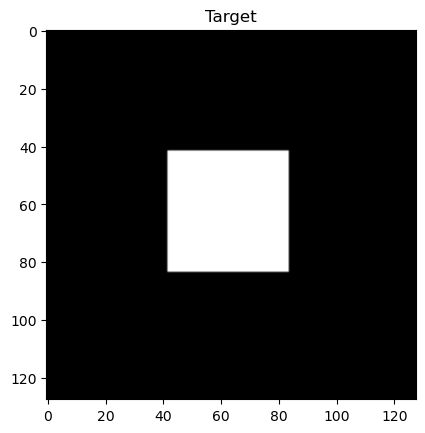

In [3]:
S = 128
target = np.zeros((S,S))
target[int(S/3):2*int(S/3),int(S/3):2*int(S/3)] = 1.0
# target[120:136,100:116] = 1.0

plt.figure()
plt.title("Target")
plt.imshow(target, cmap='gray')
plt.show()

In [4]:
# Funções auxiliares

# programa que converte matriz de pixels em matriz que 
# cada elemento corresponde a um pixel preto e branco
def converter_matriz(matriz):
    N = np.shape(matriz)[0]
    origem = N/2 #Corresponde a coordenada da origem (em x ou y) 
    
    new_matriz = np.zeros((N,N))
    for i in range(N):
        for j in range(N):
            new_matriz[i,j] = np.max(matriz_pixels[i,j,:])
            
    return new_matriz

# arredonda um número
def arredondar(number):
    if number < 0:
        if int(number) - number >= 0.5:
            return int(number)-1
        else:
            return int(number)
    else:
        if number - int(number) >= 0.5:
            return int(number)+1
        else:
            return int(number)

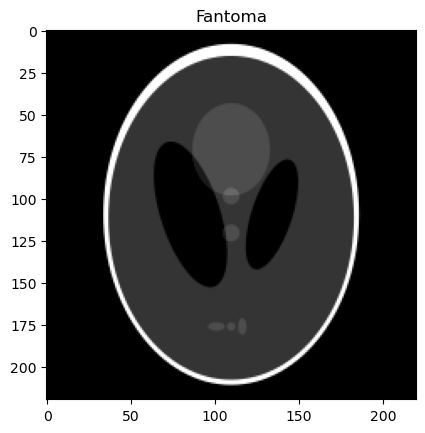

In [6]:
# Obtem imagem em formato de array c\ filtro aplicado
imagem = Image.open('SheppLogan_Phantom.png')
matriz_pixels = np.array(imagem)
matriz = converter_matriz(matriz_pixels)

plt.imshow(matriz, cmap= 'gray')
plt.title('Fantoma')
plt.show()

### a) Criação do sinograma

A função ira receber como input uma matriz que ontém o valor dos pixels de uma imagem em preto e branco e o número de fatias em que se quer dividir o intervalo de $[0,\pi]$.

A para cada angulo no intervalo, a função irá rodar a matriz com no angulo condizente. De seguida, para cada linha da matriz, irá somar todos os valores desta linha, o array correspondente a soma destes valores para todas as linhas será uma coluna do sinograma.

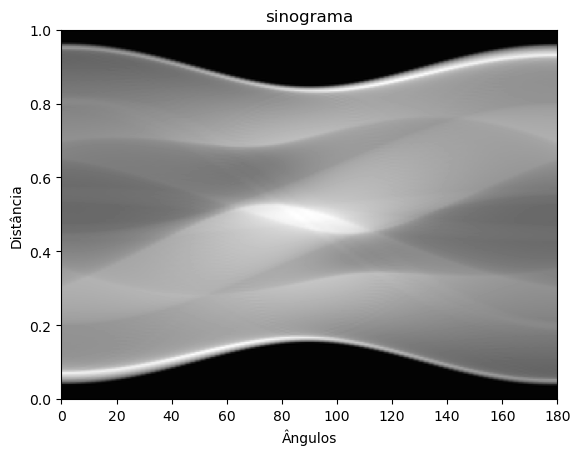

In [7]:
def constroi_sinograma(matriz, n):
    # Difinições úteis
    angles = np.linspace(0, 180, n)
    N = np.shape(matriz)[0]
    origem = int(N/2)
    
    sinogram = np.zeros((N, n))
    
    for s in range(n):
        matriz_rodada = scipy.ndimage.rotate(matriz, angles[s], reshape = False)
        
        for i in range(N):
            j = arredondar(np.sqrt(2*i*origem - i**2))
            sinogram[i,s] = np.sum(matriz_rodada[i,origem - j:origem + j])
                
    return sinogram

n = 100
sinograma = constroi_sinograma(matriz, n)


plt.imshow(sinograma, cmap = 'gray', extent = [0,180,0,1], origin = 'lower')
plt.gca().set_aspect('auto')
plt.title('sinograma')
plt.xlabel('Ângulos')
plt.ylabel('Distância')
plt.show()

### b) Retroprojeção não filtrada

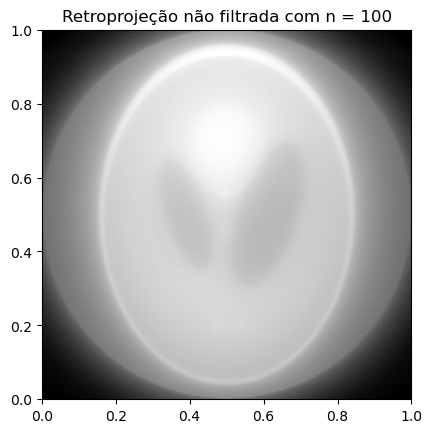

In [8]:

def retroprojecao_n_filtrada(sinograma):
    N,n = np.shape(sinograma)
    angles = np.linspace(0,180,n)

    reconstrucao_img = np.zeros((N,N))
    for s in range(n):
        retroprojecao = np.tile(sinograma[:,s][:,np.newaxis],(1, N))
        retroprojecao = scipy.ndimage.rotate(retroprojecao, angles[s], reshape = False)
        reconstrucao_img += retroprojecao
    
    return reconstrucao_img

reconstrucao_img = retroprojecao_n_filtrada(sinograma)

plt.imshow(reconstrucao_img, cmap = 'gray', extent = [0,1,0,1])
plt.title(f'Retroprojeção não filtrada com n = {n}')
plt.show()

### c) Retroprojeção filtrada

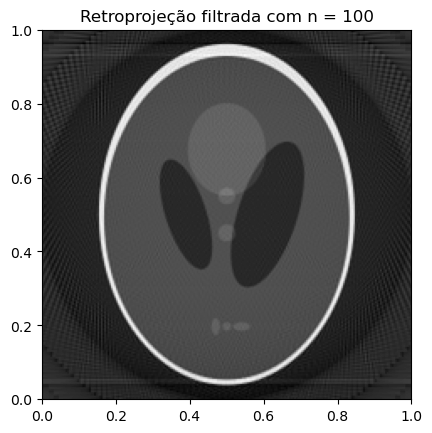

In [9]:
def retroprojecao_filtrada(sinograma):
    N,n = np.shape(sinograma)
    angles = np.linspace(0,180,n)
    
    reconstrucao_img = np.zeros((N,N))
    for s in range(n):
        t_fourier = np.fft.fft(sinograma[:,s])
        freq = np.fft.fftfreq(N)
        
        it_fourier = np.fft.ifft(abs(freq)*t_fourier)
        
        retroprojecao = np.tile(it_fourier[:,np.newaxis],(1, N))
        retroprojecao = scipy.ndimage.rotate(retroprojecao, angles[s], reshape = False)
        reconstrucao_img += retroprojecao.real
    
    return reconstrucao_img
    
reconstrucao_img = retroprojecao_filtrada(sinograma)

plt.imshow(reconstrucao_img, cmap = 'gray', extent = [0,1,0,1])
plt.title(f'Retroprojeção filtrada com n = {n}')
plt.show()

### d) Comparação dos dois métodos

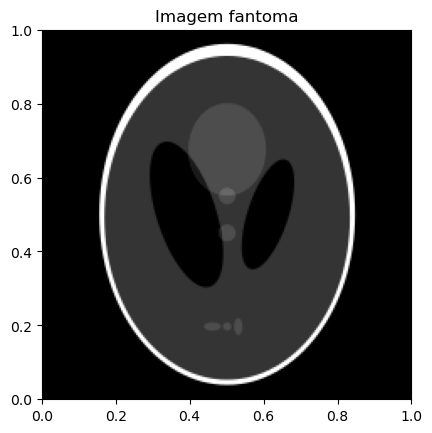

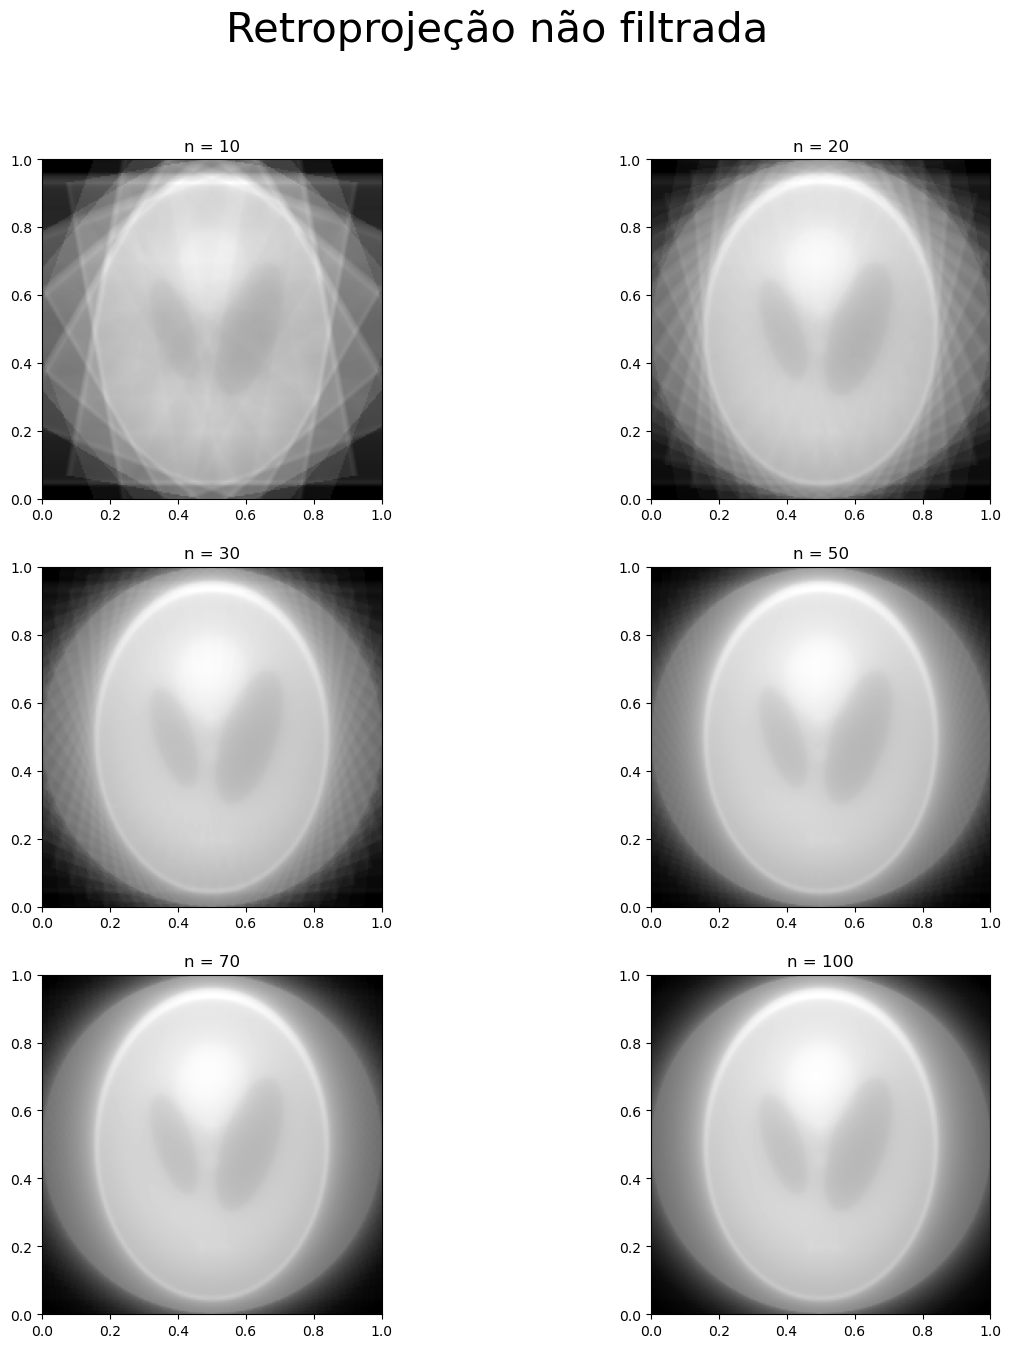

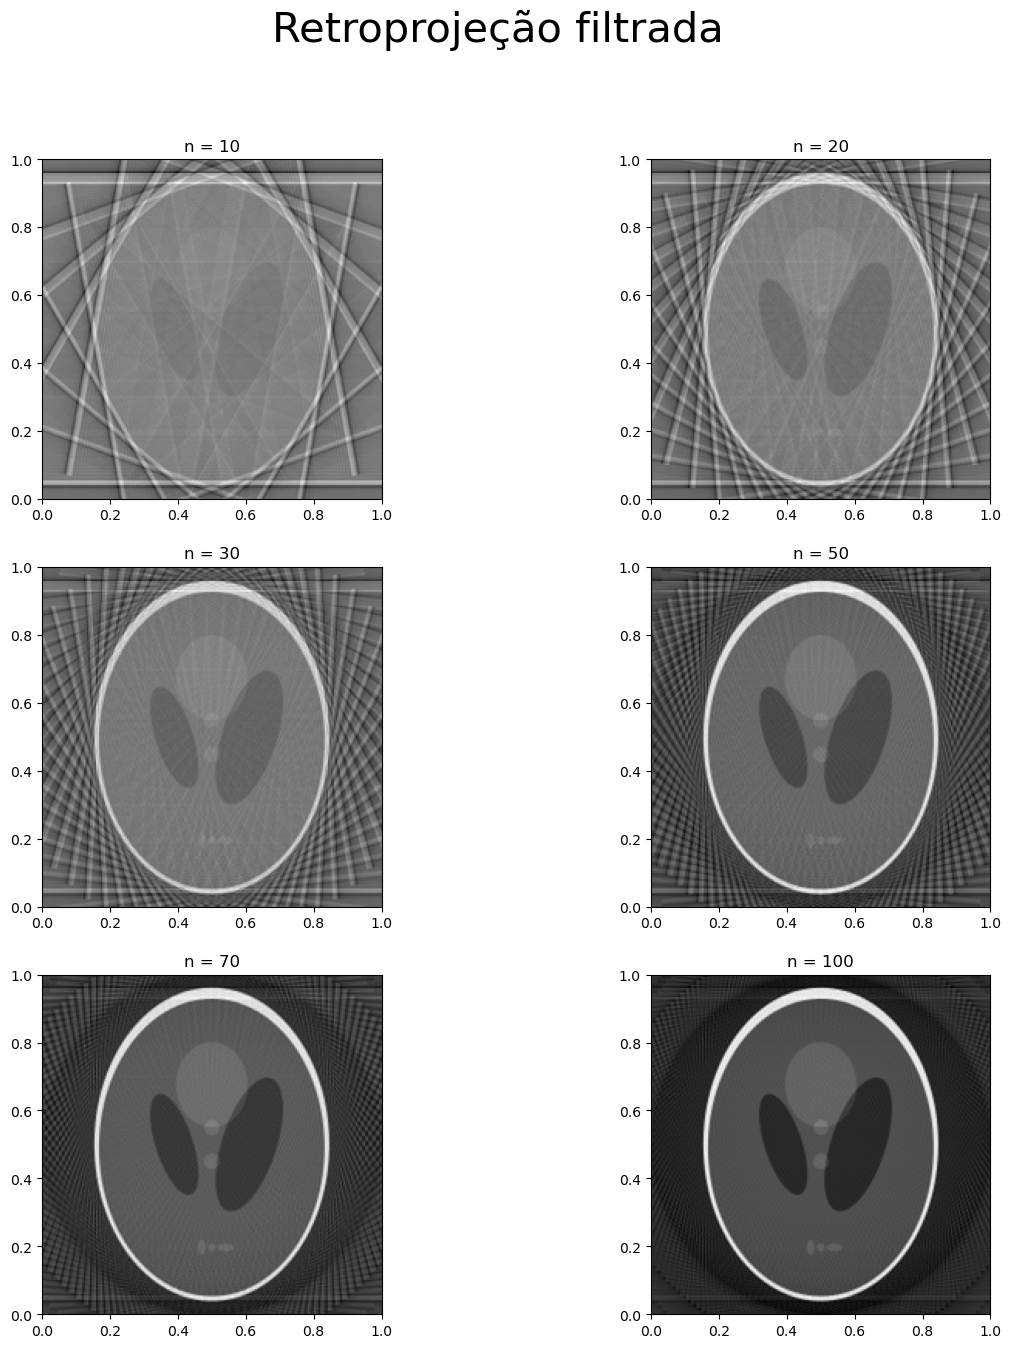

In [11]:
plt.imshow(matriz, cmap= 'gray', extent = [0,1,0,1])
plt.title('Imagem fantoma')
plt.show()

ns = np.array([10,20,30,50,70,100])

plt.figure(figsize=(15, 15)) 
for i in range(len(ns)):
    reconstrucao = retroprojecao_n_filtrada(constroi_sinograma(matriz, ns[i]))
    
   
    ax  = plt.subplot(3,2,i+1)
    plt.imshow(reconstrucao, cmap = 'gray', extent = [0,1,0,1])
    ax.set_title(f'n = {ns[i]}')
   
plt.subplots_adjust(hspace=0.2, wspace=0.1)
plt.suptitle('Retroprojeção não filtrada', fontsize = 30)
plt.show()

plt.figure(figsize=(15, 15)) 
for i in range(len(ns)):
    reconstrucao = retroprojecao_filtrada(constroi_sinograma(matriz, ns[i]))
    
   
    ax  = plt.subplot(3,2,i+1)
    plt.imshow(reconstrucao, cmap = 'gray', extent = [0,1,0,1])
    ax.set_title(f'n = {ns[i]}')
   
plt.subplots_adjust(hspace=0.2, wspace=0.1)
plt.suptitle('Retroprojeção filtrada', fontsize = 30)
plt.show()